In [1]:
import subprocess, sys

for pkg in ['lightgbm', 'catboost', 'optuna']:
    try:
        __import__(pkg)
        print(f'  ✓ {pkg}')
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
        print(f'  ✓ {pkg} installed')

print('\nAll packages ready.')

  ✓ lightgbm
  ✓ catboost
  ✓ optuna

All packages ready.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import lightgbm as lgb
from catboost import CatBoostRegressor

SEED = 42
N_FOLDS = 5
TARGET_CAP_QUANTILE = 0.995 
np.random.seed(SEED)
pd.set_option('display.max_columns', None)

print(f'LightGBM : {lgb.__version__}')
print('Imports done.')

LightGBM : 4.6.0
Imports done.


In [3]:
def find_csv(name):
    for root in ['/kaggle/input/flight-price-prediction',
                 '/kaggle/input',
                 '/content/drive/MyDrive/ML Projects/ML_P1_Regression',
                 '.']:
        p = Path(root)
        if not p.exists(): continue
        for f in p.rglob(name):
            return f
    raise FileNotFoundError(f'{name} not found')

train_df = pd.read_csv(find_csv('train.csv'))
test_df  = pd.read_csv(find_csv('test.csv'))
sub_df   = pd.read_csv(find_csv('submission.csv'))

TARGET = 'price'
print(f'Train : {train_df.shape}')
print(f'Test  : {test_df.shape}')
print(f'Price stats: mean={train_df[TARGET].mean():.1f}, max={train_df[TARGET].max()}')
display(train_df.head(3))

Train : (18076, 12)
Test  : (4520, 11)
Price stats: mean=280.3, max=8996


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129


In [4]:
def engineer_features(df):
    X = df.copy()

    X['stops_num'] = X['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2}).fillna(1).astype(int)

    time_ord = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2,
                'Evening': 3, 'Night': 4, 'Late_Night': 5}
    X['dep_time_num'] = X['departure_time'].map(time_ord).fillna(2).astype(int)
    X['arr_time_num'] = X['arrival_time'].map(time_ord).fillna(2).astype(int)
    X['time_diff']    = (X['arr_time_num'] - X['dep_time_num']).abs()  # same-period vs overnight

    X['is_business']      = (X['flight_class'] == 'Business').astype(int)
    X['is_nonstop']       = (X['stops'] == 'zero').astype(int)
    X['is_last_minute']   = (X['days_left'] <= 3).astype(int)
    X['is_same_week']     = (X['days_left'] <= 7).astype(int)
    X['is_advance']       = (X['days_left'] >= 30).astype(int)
    X['is_very_advance']  = (X['days_left'] >= 60).astype(int)

    X['route']         = X['source_city'] + '__' + X['destination_city']
    X['route_reverse'] = X['destination_city'] + '__' + X['source_city']  # symmetry

    X['airline_class']  = X['airline'] + '__' + X['flight_class']
    X['route_class']    = X['route']   + '__' + X['flight_class']
    X['route_stops']    = X['route']   + '__' + X['stops']
    X['airline_route']  = X['airline'] + '__' + X['route']
    X['airline_stops']  = X['airline'] + '__' + X['stops']
    X['class_stops']    = X['flight_class'] + '__' + X['stops']
    X['dep_arr_time']   = X['departure_time'] + '__' + X['arrival_time']
    X['airline_route_class'] = X['airline'] + '__' + X['route'] + '__' + X['flight_class']

    d = X['days_left'].clip(0)
    X['days_left_sq']   = d ** 2
    X['days_left_log']  = np.log1p(d)
    X['days_left_sqrt'] = np.sqrt(d)
    X['days_left_inv']  = 1.0 / (d + 1)  

    dur = X['duration'].clip(0)
    X['duration_sq']    = dur ** 2
    X['duration_log']   = np.log1p(dur)
    X['duration_sqrt']  = np.sqrt(dur)

    X['duration_x_stops']      = dur * X['stops_num']
    X['total_travel_time']     = dur * (X['stops_num'] + 1)
    X['duration_x_days_log']   = dur * X['days_left_log']
    X['business_x_days_sq']    = X['is_business'] * X['days_left_sq']
    X['business_x_duration']   = X['is_business'] * dur
    X['business_x_stops']      = X['is_business'] * X['stops_num']
    X['lastmin_x_business']    = X['is_last_minute'] * X['is_business']
    X['advance_x_business']    = X['is_advance'] * X['is_business']
    X['stops_x_days_inv']      = X['stops_num'] * X['days_left_inv']
    X['nonstop_x_business']    = X['is_nonstop'] * X['is_business']

    return X

train_feat = engineer_features(train_df)
test_feat  = engineer_features(test_df)
print(f'After engineering — Train: {train_feat.shape}, Test: {test_feat.shape}')

After engineering — Train: (18076, 49), Test: (4520, 48)


In [5]:
CAT_FEATURES = [
    'airline', 'source_city', 'destination_city',
    'departure_time', 'arrival_time', 'stops', 'flight_class',
    'route', 'route_reverse',
    'airline_class', 'route_class', 'route_stops',
    'airline_route', 'airline_stops', 'class_stops',
    'dep_arr_time', 'airline_route_class'
]

NUM_FEATURES = [
    'duration', 'days_left',
    'stops_num', 'dep_time_num', 'arr_time_num', 'time_diff',
    'is_business', 'is_nonstop',
    'is_last_minute', 'is_same_week', 'is_advance', 'is_very_advance',
    'days_left_sq', 'days_left_log', 'days_left_sqrt', 'days_left_inv',
    'duration_sq', 'duration_log', 'duration_sqrt',
    'duration_x_stops', 'total_travel_time', 'duration_x_days_log',
    'business_x_days_sq', 'business_x_duration', 'business_x_stops',
    'lastmin_x_business', 'advance_x_business',
    'stops_x_days_inv', 'nonstop_x_business'
]

ALL_FEATURES = CAT_FEATURES + NUM_FEATURES

train_clean = train_feat.copy().reset_index(drop=True)
print(f'Keeping all {len(train_clean)} rows and their original target values.')

def encode_cats(df):
    df = df.copy()
    for col in CAT_FEATURES:
        df[col] = df[col].astype('category')
    return df

X_all  = encode_cats(train_clean[ALL_FEATURES])
X_test = encode_cats(test_feat[ALL_FEATURES])

for col in CAT_FEATURES:
    X_test[col] = pd.Categorical(X_test[col], categories=X_all[col].cat.categories)

y_raw = train_clean[TARGET].values

print(f'\nX_all  : {X_all.shape}')
print(f'X_test : {X_test.shape}')
print(f'Features: {len(ALL_FEATURES)} ({len(CAT_FEATURES)} cat + {len(NUM_FEATURES)} num)')
print(f'y_raw  — mean: {y_raw.mean():.1f}, std: {y_raw.std():.1f}, max: {y_raw.max():.0f}')

Keeping all 18076 rows and their original target values.

X_all  : (18076, 46)
X_test : (4520, 46)
Features: 46 (17 cat + 29 num)
y_raw  — mean: 280.3, std: 222.0, max: 8996


In [6]:
stop_bucket = train_clean['stops'].map({'zero': 'S0', 'one': 'S1', 'two_or_more': 'S2'}).fillna('S1')
strat_key   = train_clean['flight_class'].astype(str) + '_' + stop_bucket.astype(str)

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb_raw = np.zeros(len(X_all))
test_lgb_folds = []
fold_metrics = []

lgb_params = dict(
    objective         = 'regression',
    metric            = 'rmse',
    n_estimators      = 8000,       
    learning_rate     = 0.015,       
    num_leaves        = 255,         
    max_depth         = -1,
    min_child_samples = 20,
    subsample         = 0.80,
    subsample_freq    = 1,
    colsample_bytree  = 0.70,        
    reg_lambda        = 2.0,
    reg_alpha         = 0.1,
    min_split_gain    = 0.001,
    random_state      = SEED,
    verbosity         = -1,
    n_jobs            = -1
)

print('Running 5-Fold LightGBM (Stratified on class × stops)...')
print('=' * 70)

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all, strat_key), 1):
    X_tr, X_val   = X_all.iloc[tr_idx],   X_all.iloc[val_idx]
    y_tr_raw = y_raw[tr_idx]
    y_tr = y_tr_raw.copy()
    fold_classes = train_clean['flight_class'].iloc[tr_idx].to_numpy()
    for cls in np.unique(fold_classes):
        cls_mask = fold_classes == cls
        cap = np.quantile(y_tr_raw[cls_mask], TARGET_CAP_QUANTILE)
        y_tr[cls_mask] = np.minimum(y_tr[cls_mask], cap)

    y_val = y_raw[val_idx]
    y_val_raw = y_val 

    model = lgb.LGBMRegressor(**lgb_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        categorical_feature=CAT_FEATURES,
        callbacks=[
            lgb.early_stopping(200, verbose=False),
            lgb.log_evaluation(period=-1)
        ]
    )

    val_pred_raw = model.predict(X_val, num_iteration=model.best_iteration_)
    oof_lgb_raw[val_idx] = val_pred_raw

    test_lgb_folds.append(model.predict(X_test, num_iteration=model.best_iteration_))

    rmse = mean_squared_error(y_val_raw, val_pred_raw) ** 0.5
    mae  = mean_absolute_error(y_val_raw, val_pred_raw)
    r2   = r2_score(y_val_raw, val_pred_raw)
    fold_metrics.append({'Fold': fold, 'Best Iter': model.best_iteration_,
                         'RMSE': rmse, 'MAE': mae, 'R2': r2})
    print(f'Fold {fold} | iter={model.best_iteration_:5d} | RMSE={rmse:8.2f} | MAE={mae:7.2f} | R²={r2:.5f}')

print('=' * 70)
metrics_df = pd.DataFrame(fold_metrics)
display(metrics_df)

lgb_oof_r2   = r2_score(y_raw, oof_lgb_raw)
lgb_oof_rmse = mean_squared_error(y_raw, oof_lgb_raw) ** 0.5
lgb_oof_mae  = mean_absolute_error(y_raw, oof_lgb_raw)

print(f'\n>>> LightGBM OOF R²   : {lgb_oof_r2:.6f}  ({lgb_oof_r2*100:.2f}%)')
print(f'>>> LightGBM OOF RMSE : {lgb_oof_rmse:.4f}')
print(f'>>> LightGBM OOF MAE  : {lgb_oof_mae:.4f}')

Running 5-Fold LightGBM (Stratified on class × stops)...
Fold 1 | iter=  838 | RMSE=  158.71 | MAE=  43.55 | R²=0.59568
Fold 2 | iter=  643 | RMSE=  131.30 | MAE=  44.63 | R²=0.67227
Fold 3 | iter=  614 | RMSE=   96.88 | MAE=  41.82 | R²=0.79190
Fold 4 | iter=  505 | RMSE=   99.45 | MAE=  41.98 | R²=0.76262
Fold 5 | iter=  949 | RMSE=  111.51 | MAE=  44.65 | R²=0.72145


,Fold,Best Iter,RMSE,MAE,R2
0,1,838,158.714979,43.545453,0.595684
1,2,643,131.300481,44.631178,0.672271
2,3,614,96.876865,41.819083,0.791897
3,4,505,99.453648,41.980468,0.762619
4,5,949,111.509303,44.652025,0.721454



>>> LightGBM OOF R²   : 0.699006  (69.90%)
>>> LightGBM OOF RMSE : 121.7732
>>> LightGBM OOF MAE  : 43.3257


In [7]:
CAT_FEATURES_STR = CAT_FEATURES  

def encode_cats_str(df):
    df = df.copy()
    for col in CAT_FEATURES_STR:
        df[col] = df[col].astype(str).fillna('Unknown')
    for col in NUM_FEATURES:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    return df

X_all_cb  = encode_cats_str(train_clean[ALL_FEATURES])
X_test_cb = encode_cats_str(test_feat[ALL_FEATURES])

oof_cb_raw  = np.zeros(len(X_all_cb))
test_cb_folds = []

cb_params = dict(
    iterations     = 4000,
    learning_rate  = 0.03,
    depth          = 8,
    l2_leaf_reg    = 5.0,
    loss_function  = 'RMSE',
    random_seed    = SEED,
    random_strength= 0.5,
    verbose        = False,
    allow_writing_files = False,
    thread_count   = -1
)

print('Running 5-Fold CatBoost (Stratified on class × stops)...')
print('=' * 70)

cb_fold_metrics = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all_cb, strat_key), 1):
    X_tr, X_val  = X_all_cb.iloc[tr_idx],   X_all_cb.iloc[val_idx]
    y_tr_raw = y_raw[tr_idx]
    y_tr = y_tr_raw.copy()
    fold_classes = train_clean['flight_class'].iloc[tr_idx].to_numpy()
    for cls in np.unique(fold_classes):
        cls_mask = fold_classes == cls
        cap = np.quantile(y_tr_raw[cls_mask], TARGET_CAP_QUANTILE)
        y_tr[cls_mask] = np.minimum(y_tr[cls_mask], cap)

    y_val = y_raw[val_idx]
    y_val_raw = y_val  
    model_cb = CatBoostRegressor(**cb_params)

    model_cb.fit(
        X_tr, y_tr,
        cat_features=CAT_FEATURES_STR,
        eval_set=(X_val, y_val),
        early_stopping_rounds=150,
        verbose=False
    )

    val_pred_raw = model_cb.predict(X_val)

    oof_cb_raw[val_idx] = val_pred_raw
    test_cb_folds.append(model_cb.predict(X_test_cb))

    rmse = mean_squared_error(y_val_raw, val_pred_raw) ** 0.5
    mae  = mean_absolute_error(y_val_raw, val_pred_raw)
    r2   = r2_score(y_val_raw, val_pred_raw)
    cb_fold_metrics.append({'Fold': fold, 'Best Iter': model_cb.get_best_iteration(),
                            'RMSE': rmse, 'MAE': mae, 'R2': r2})
    print(f'Fold {fold} | iter={model_cb.get_best_iteration():5d} | RMSE={rmse:8.2f} | MAE={mae:7.2f} | R²={r2:.5f}')

print('=' * 70)
display(pd.DataFrame(cb_fold_metrics))

cb_oof_r2   = r2_score(y_raw, oof_cb_raw)
cb_oof_rmse = mean_squared_error(y_raw, oof_cb_raw) ** 0.5
print(f'\n>>> CatBoost OOF R²   : {cb_oof_r2:.6f}  ({cb_oof_r2*100:.2f}%)')
print(f'>>> CatBoost OOF RMSE : {cb_oof_rmse:.4f}')

Running 5-Fold CatBoost (Stratified on class × stops)...
Fold 1 | iter= 1574 | RMSE=  160.99 | MAE=  46.84 | R²=0.58400
Fold 2 | iter= 3231 | RMSE=  132.20 | MAE=  47.65 | R²=0.66775
Fold 3 | iter= 3961 | RMSE=   96.66 | MAE=  42.96 | R²=0.79281
Fold 4 | iter= 2857 | RMSE=  100.44 | MAE=  45.08 | R²=0.75787
Fold 5 | iter= 3900 | RMSE=  110.64 | MAE=  45.69 | R²=0.72576


,Fold,Best Iter,RMSE,MAE,R2
0,1,1574,160.991246,46.838452,0.584003
1,2,3231,132.203084,47.651583,0.667750
2,3,3961,96.664145,42.961121,0.792810
3,4,2857,100.444116,45.078486,0.757868
4,5,3900,110.644000,45.691768,0.725760



>>> CatBoost OOF R²   : 0.695229  (69.52%)
>>> CatBoost OOF RMSE : 122.5348


In [8]:
best_w, best_blend_r2 = 0.5, -np.inf

print('Grid search for best LightGBM/CatBoost blend weight using OOF predictions...')
results = []
for w_lgb in np.arange(0.0, 1.01, 0.05):
    blend = w_lgb * oof_lgb_raw + (1 - w_lgb) * oof_cb_raw
    r2    = r2_score(y_raw, blend)
    results.append({'w_lgb': round(w_lgb, 2), 'blend_R2': r2})
    if r2 > best_blend_r2:
        best_blend_r2, best_w = r2, w_lgb

results_df = pd.DataFrame(results)
display(results_df.sort_values('blend_R2', ascending=False).head(10))

print(f'\nBest blend: {best_w:.2f} × LightGBM + {1-best_w:.2f} × CatBoost')
print(f'Best OOF R²: {best_blend_r2:.6f}  ({best_blend_r2*100:.2f}%)')
print(f'\nIndividual OOF R²:')
print(f'  LightGBM : {lgb_oof_r2:.6f}')
print(f'  CatBoost : {cb_oof_r2:.6f}')
print(f'  Blend    : {best_blend_r2:.6f}')

Grid search for best LightGBM/CatBoost blend weight using OOF predictions...


,w_lgb,blend_R2
12,0.60,0.702148
11,0.55,0.702104
13,0.65,0.702094
10,0.50,0.701964
14,0.70,0.701944
9,0.45,0.701726
15,0.75,0.701696
8,0.40,0.701392
16,0.80,0.701352
7,0.35,0.700961



Best blend: 0.60 × LightGBM + 0.40 × CatBoost
Best OOF R²: 0.702148  (70.21%)

Individual OOF R²:
  LightGBM : 0.699006
  CatBoost : 0.695229
  Blend    : 0.702148


In [9]:
test_lgb_avg = np.mean(test_lgb_folds, axis=0)
test_cb_avg  = np.mean(test_cb_folds,  axis=0)

test_final = best_w * test_lgb_avg + (1 - best_w) * test_cb_avg
test_final = np.clip(test_final, 0, None) 

print('Test prediction summary:')
print(pd.Series(test_final).describe().round(2))

pred_map  = pd.Series(test_final, index=test_df['id'].values)
submission = sub_df.copy()
submission['price'] = submission['id'].map(pred_map)

missing = submission['price'].isna().sum()
assert missing == 0, f'ERROR: {missing} missing predictions — check ID alignment!'

print(f'\nSubmission shape : {submission.shape}')
print(f'Price range      : {submission["price"].min():.2f} — {submission["price"].max():.2f}')
print(f'Price mean       : {submission["price"].mean():.2f}')
display(submission.head(10))

submission.to_csv('submission_winning.csv', index=False)
print('\nSaved: submission_winning.csv  ← SUBMIT THIS!')

Test prediction summary:
count    4520.00
mean      279.66
std       180.71
min        24.29
25%       158.98
50%       241.67
75%       348.11
max      1655.35
dtype: float64

Submission shape : (4520, 2)
Price range      : 24.29 — 1655.35
Price mean       : 279.66


,id,price
0,18395,65.870913
1,11771,169.111247
2,22326,427.723982
3,18332,126.996116
4,11021,559.522148
5,8614,213.180051
6,17654,154.638556
7,14898,174.583196
8,8794,142.796190
9,15325,176.976044



Saved: submission_winning.csv  ← SUBMIT THIS!


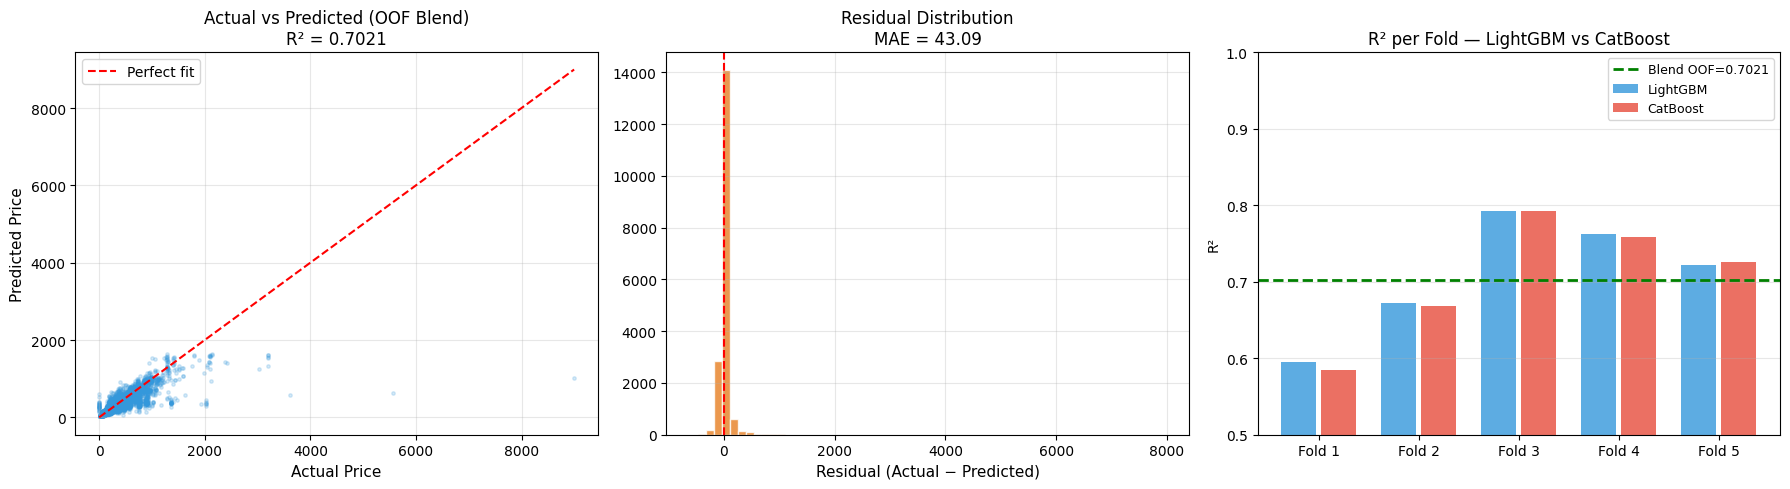

FINAL RESULTS
  LightGBM OOF R²   : 0.699006
  CatBoost OOF R²   : 0.695229
  BLEND OOF R²      : 0.702148  (70.21%)
Submit: submission_winning.csv


In [10]:

oof_blend = best_w * oof_lgb_raw + (1 - best_w) * oof_cb_raw

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_raw, oof_blend, alpha=0.2, s=6, color='#3498db')
mx = max(y_raw.max(), oof_blend.max())
axes[0].plot([0, mx], [0, mx], 'r--', lw=1.5, label='Perfect fit')
axes[0].set_xlabel('Actual Price', fontsize=11)
axes[0].set_ylabel('Predicted Price', fontsize=11)
axes[0].set_title(f'Actual vs Predicted (OOF Blend)\nR² = {best_blend_r2:.4f}', fontsize=12)
axes[0].legend(); axes[0].grid(alpha=0.3)

res = y_raw - oof_blend
axes[1].hist(res, bins=60, color='#e67e22', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', lw=1.5, linestyle='--')
axes[1].set_xlabel('Residual (Actual − Predicted)', fontsize=11)
axes[1].set_title(f'Residual Distribution\nMAE = {mean_absolute_error(y_raw, oof_blend):.2f}', fontsize=12)
axes[1].grid(alpha=0.3)

lgb_r2s = [m['R2'] for m in fold_metrics]
cb_r2s  = [m['R2'] for m in cb_fold_metrics]
x = np.arange(N_FOLDS)
axes[2].bar(x - 0.2, lgb_r2s, 0.35, label='LightGBM', color='#3498db', alpha=0.8)
axes[2].bar(x + 0.2, cb_r2s,  0.35, label='CatBoost',  color='#e74c3c', alpha=0.8)
axes[2].axhline(best_blend_r2, color='green', lw=2, linestyle='--', label=f'Blend OOF={best_blend_r2:.4f}')
axes[2].set_xticks(x); axes[2].set_xticklabels([f'Fold {i+1}' for i in x])
axes[2].set_ylim(0.5, 1.0); axes[2].set_ylabel('R²')
axes[2].set_title('R² per Fold — LightGBM vs CatBoost', fontsize=12)
axes[2].legend(fontsize=9); axes[2].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'='*60}")
print(f'FINAL RESULTS')
print(f'  LightGBM OOF R²   : {lgb_oof_r2:.6f}')
print(f'  CatBoost OOF R²   : {cb_oof_r2:.6f}')
print(f'  BLEND OOF R²      : {best_blend_r2:.6f}  ({best_blend_r2*100:.2f}%)')
print(f"{'='*60}")
print('Submit: submission_winning.csv')